# Installation Year: Relationship and Imputation Study

## Objective

Investigate why advanced imputation methods do not consistently
outperform simple imputation for installation_year.

## Research questions

1. What is the distribution of installation_year?
2. Which attributes have relationships with installation_year?
3. How much predictive information do those relationships provide?
4. How does missingness affect reconstruction?
5. How does noise affect model performance?
6. Which conditions favour simple or advanced imputation?

## Dataset

- Asset class: Overhead conductors
- Records: 10,000
- Missingness: 20% per target attribute
- Noise scenarios: 0%, 10%, 30%, 50%
- Ground truth: Complete synthetic reference

The clean ground truth will be used for relationship analysis and
evaluation. It will not be provided to models during imputation.

### 1. Imports and dataset configuration

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

# Change this if your files are stored elsewhere.
# DATA_DIR = Path("outputs/team19_shared_data/final_dataset")

DATA_FOLDER = Path("outputs/team19_shared/final_datasets")

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / DATA_FOLDER).is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot locate {DATA_FOLDER} from {Path.cwd()}"
    )

DATA_DIR = PROJECT_ROOT / DATA_FOLDER

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)

CLEAN_PATH = DATA_DIR / "clean_ground_truth.csv"

MASKED_PATHS = {
    0: DATA_DIR / "masked_noise_0.csv",
    10: DATA_DIR / "masked_noise_10.csv",
    30: DATA_DIR / "masked_noise_30.csv",
    50: DATA_DIR / "masked_noise_50.csv",
}

TARGET = "installation_year"

TARGET_COLUMNS = [
    "installation_year",
    "distance_to_sea_km",
    "length_km",
    "voltage_category",
    "location_group",
    "corrosion_zone",
    "material",
    "covering",
]

required_files = [CLEAN_PATH, *MASKED_PATHS.values()]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file: {path.resolve()}"
        )

print("All dataset files found.")

Project root: /Users/zisanaalam/Desktop/GitHub/team19-asset-data
Dataset directory: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/outputs/team19_shared/final_datasets
All dataset files found.


### 2. Load and validate

In [5]:
clean = pd.read_csv(CLEAN_PATH)
masked = {
    noise: pd.read_csv(path)
    for noise, path in MASKED_PATHS.items()
}

assert clean["segment_id"].is_unique

clean = clean.set_index("segment_id")

for noise, df in masked.items():
    assert df["segment_id"].is_unique

    df = df.set_index("segment_id")

    assert set(df.index) == set(clean.index), (
        f"Row IDs differ at {noise}% noise"
    )

    masked[noise] = df.loc[clean.index]

print("Total clean records:", len(clean))
print("Clean dataset columns:", len(clean.columns))

print("\nInstallation year:")
print(clean[TARGET].describe())

print("\nMissing values per noise scenario:")

for noise, df in masked.items():
    missing = df[TARGET].isna().sum()

    print(f"{noise}% noise: {missing} missing")

    assert missing == 2000

print("\nChecking identical installation-year masks:")

reference_mask = masked[0][TARGET].isna()

for noise, df in masked.items():
    same_mask = reference_mask.equals(df[TARGET].isna())

    print(f"{noise}% noise: {same_mask}")

    assert same_mask

print("\nDataset validation: PASSED")

Total clean records: 10000
Clean dataset columns: 12

Installation year:
count    10000.00000
mean      1963.37850
std         14.32261
min       1930.00000
25%       1955.00000
50%       1958.00000
75%       1969.00000
max       2014.00000
Name: installation_year, dtype: float64

Missing values per noise scenario:
0% noise: 2000 missing
10% noise: 2000 missing
30% noise: 2000 missing
50% noise: 2000 missing

Checking identical installation-year masks:
0% noise: True
10% noise: True
30% noise: True
50% noise: True

Dataset validation: PASSED


### 3. Understand installation-year distribution

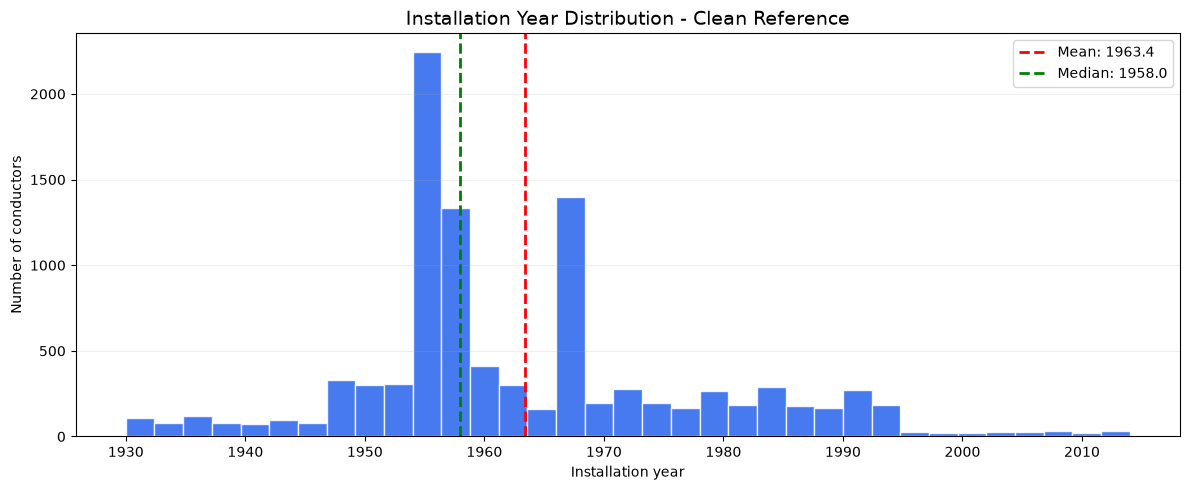

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker 

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(
    clean["installation_year"],
    bins=35,
    color="#2563eb",
    edgecolor="white",
    alpha=0.85,
)

mean_year = clean["installation_year"].mean()
median_year = clean["installation_year"].median()

ax.axvline(
    mean_year,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_year:.1f}",
)

ax.axvline(
    median_year,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_year:.1f}",
)

ax.set_title(
    "Installation Year Distribution - Clean Reference",
    fontsize=14,
)

ax.set_xlabel("Installation year")
ax.set_ylabel("Number of conductors")

# --- Add this line to force 10-year intervals ---
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

The median is approximately 5.38 years below the mean. 
The histogram shows a strong concentration around the 1950s and 1960s, along with a longer tail toward more recent installation years. 
This is consistent with the mean being greater than the median.

#### Why is this relevant?

Consider two imputation approaches.

#### Simple median imputation
Every missing installation year receives approximately:

$$
\hat{y}=1958
$$

This may produce relatively low absolute error because many assets are concentrated near that period.

#### Predictive imputation
A predictive model attempts to estimate different installation years based on other attributes. 
For example:
* Aluminium conductor $\rightarrow$ 1970
* Copper conductor $\rightarrow$ 1960
* Steel conductor $\rightarrow$ 1962

However, those predictions may not be accurate for individual records because the conditional installation-year distributions overlap.

This gives us our first hypothesis:

**H1: The concentration of installation years around the late 1950s makes median imputation a competitive baseline.**

This hypothesis is plausible, but we still need to test it.

### 4. Installation year by material and voltage

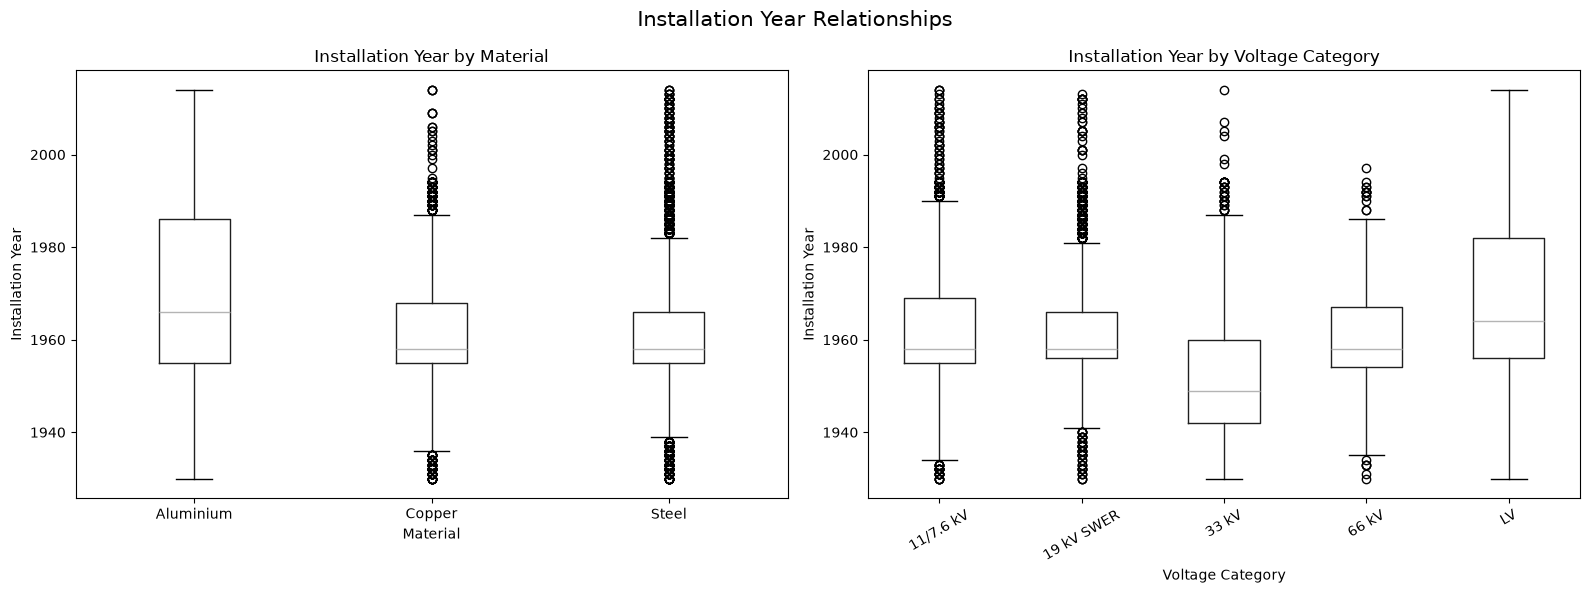

In [7]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6),
)

clean.boxplot(
    column="installation_year",
    by="material",
    ax=axes[0],
    grid=False,
)

axes[0].set_title("Installation Year by Material")
axes[0].set_xlabel("Material")
axes[0].set_ylabel("Installation Year")

clean.boxplot(
    column="installation_year",
    by="voltage_category",
    ax=axes[1],
    grid=False,
    rot=30,
)

axes[1].set_title("Installation Year by Voltage Category")
axes[1].set_xlabel("Voltage Category")
axes[1].set_ylabel("Installation Year")

fig.suptitle("Installation Year Relationships", fontsize=15)

plt.tight_layout()
plt.show()

### 5. Numerical summary by category

In [8]:
for column in ["material", "voltage_category"]:

    print(f"\nInstallation year by {column}")

    summary = (
        clean.groupby(column)["installation_year"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            min="min",
            max="max",
        )
        .round(2)
    )

    display(summary)


Installation year by material


,count,mean,median,std,min,max
material,,,,,,
Aluminium,1180,1969.82,1966.0,19.08,1930,2014
Copper,1521,1961.67,1958.0,15.37,1930,2014
Steel,7299,1962.69,1958.0,12.85,1930,2014



Installation year by voltage_category


,count,mean,median,std,min,max
voltage_category,,,,,,
11/7.6 kV,2651,1963.79,1958.0,13.26,1930,2014
19 kV SWER,4008,1963.18,1958.0,11.54,1930,2013
33 kV,943,1953.06,1949.0,15.44,1930,2014
66 kV,219,1961.08,1958.0,14.47,1930,1997
LV,2179,1967.94,1964.0,17.06,1930,2014


#### Observation 1: Intallation year by Material Result 
Aluminium conductors tend to have later installation years. 
For example:

$$
1969.82 - 1962.69 = 7.13 \text{ years}
$$

Aluminium conductors were installed approximately 7.13 years later than Steel conductors on average in this synthetic population. 
That is evidence of an association.

However, look at the standard deviations:
* Aluminium: 19.08 years
* Copper: 15.37 years
* Steel: 12.85 years

These are substantial relative to the differences between their means. 
Your boxplots confirm considerable overlap. 
For example, even though Aluminium has a later average installation year, Aluminium conductors also appear among the oldest records.

**Interpretation:** Material provides some information about installation year, but material alone cannot identify an exact installation year reliably.

### Observation 2: Installation year by voltage category: Voltage appears more informative than material

The difference between the mean installation years of 33 kV and LV conductors is:

$$
1967.94 - 1953.06 = 14.88 \text{ years}
$$

This is a substantial difference. 
It agrees with the historical-era relationships configured in our synthetic generator. 
However, your boxplots reveal that the distributions still overlap. 

Therefore:
* Voltage may help estimate installation era.
* Voltage may not be sufficient to estimate the exact installation year.
* Combining voltage with material and other predictors could improve prediction.

## 4. Quantifying Installation-Year Relationships

### Objective

Measure the strength of relationships between installation_year
and the categorical attributes available to the imputation model.

### Method

Use eta-squared to estimate the proportion of installation-year
variation associated with each categorical attribute.

### Hypothesis

Material and voltage category are related to installation year,
but their individual relationships may explain only a limited
proportion of installation-year variation.

In [11]:
def eta_squared(df, categorical_column, numeric_column):
    """
    Calculate eta-squared for a categorical predictor
    and a numerical target.
    """

    data = df[
        [categorical_column, numeric_column]
    ].dropna()

    overall_mean = data[numeric_column].mean()

    ss_total = (
        (data[numeric_column] - overall_mean) ** 2
    ).sum()

    ss_between = 0.0

    for _, group in data.groupby(categorical_column):
        group_mean = group[numeric_column].mean()

        ss_between += (
            len(group) * (group_mean - overall_mean) ** 2
        )

    if ss_total == 0:
        return np.nan

    return ss_between / ss_total


categorical_predictors = [
    "material",
    "voltage_category",
    "location_group",
    "corrosion_zone",
    "covering",
]

relationship_results = []

for column in categorical_predictors:

    score = eta_squared(
        clean,
        column,
        "installation_year",
    )

    relationship_results.append({
        "attribute": column,
        "eta_squared": score,
        "variance_percentage": score * 100,
    })


relationship_df = pd.DataFrame(
    relationship_results
).sort_values(
    "eta_squared",
    ascending=False,
)

display(relationship_df.round(4))

,attribute,eta_squared,variance_percentage
1,voltage_category,0.0719,7.1891
0,material,0.0277,2.7680
4,covering,0.0058,0.5803
2,location_group,0.0016,0.1555
3,corrosion_zone,0.0002,0.0197


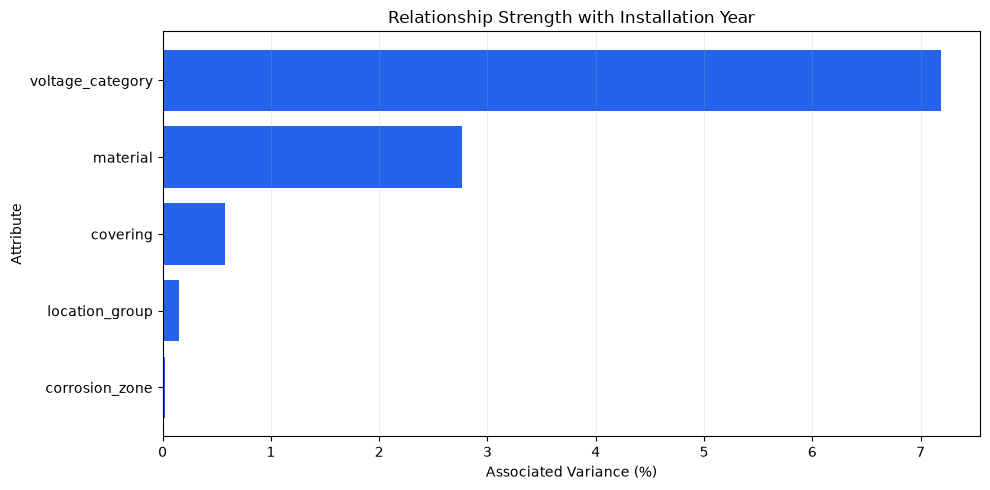

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    relationship_df["attribute"],
    relationship_df["variance_percentage"],
    color="#2563eb",
)

ax.set_xlabel("Associated Variance (%)")
ax.set_ylabel("Attribute")

ax.set_title(
    "Relationship Strength with Installation Year"
)

ax.invert_yaxis()

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

## 5. Predictive Information Experiment

### Objective

Determine whether the relationships present in the complete
synthetic dataset provide enough information to predict
installation_year more accurately than the global median.

### Experimental setup

- Training: 8,000 records with observed installation years.
- Testing: The same 2,000 records hidden by MF01.
- Predictors: Clean values from the synthetic reference.
- Ground truth: Used only for evaluation of hidden installation years.

### Methods

1. Global median
2. Voltage-group median
3. Voltage + material-group median
4. Random Forest regression

### Hypothesis

H2: Even with complete predictors, advanced prediction will
provide only a modest improvement over global median imputation.

In [13]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline


NUMERIC_FEATURES = [
    "distance_to_sea_km",
]

CATEGORICAL_FEATURES = [
    "voltage_category",
    "location_group",
    "corrosion_zone",
    "material",
    "covering",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


# Use the existing MF01 installation-year mask.
year_missing = masked[0]["installation_year"].isna()

train_mask = ~year_missing
test_mask = year_missing


# Clean predictor values are used intentionally
# for this oracle-information experiment.
X_train = clean.loc[train_mask, FEATURES].copy()
X_test = clean.loc[test_mask, FEATURES].copy()


# Training labels come only from observed values.
y_train = masked[0].loc[
    train_mask, "installation_year"
].astype(float)

# Hidden ground truth is reserved for evaluation.
y_test = clean.loc[
    test_mask, "installation_year"
].astype(float)


print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nPredictors:")
print(FEATURES)

assert len(X_train) == 8000
assert len(X_test) == 2000
assert X_train.notna().all().all()
assert X_test.notna().all().all()

print("\nPreparation: PASSED")

Training records: 8000
Testing records: 2000

Predictors:
['distance_to_sea_km', 'voltage_category', 'location_group', 'corrosion_zone', 'material', 'covering']

Preparation: PASSED


In [14]:
# 1. Global median
global_median = y_train.median()

pred_global = np.full(
    len(X_test),
    global_median,
)


# 2. Voltage-group median
voltage_medians = (
    pd.DataFrame({
        "voltage_category": X_train["voltage_category"],
        "year": y_train,
    })
    .groupby("voltage_category")["year"]
    .median()
)

pred_voltage = (
    X_test["voltage_category"]
    .map(voltage_medians)
    .fillna(global_median)
    .to_numpy()
)


# 3. Voltage + material conditional median
training_groups = X_train[
    ["voltage_category", "material"]
].copy()

training_groups["year"] = y_train


pair_medians = (
    training_groups
    .groupby(
        ["voltage_category", "material"]
    )["year"]
    .median()
)


test_keys = pd.MultiIndex.from_frame(
    X_test[["voltage_category", "material"]]
)

pred_pair = pd.Series(
    pair_medians.reindex(test_keys).to_numpy(),
    index=X_test.index,
)

# Fallback for combinations absent from training.
pred_pair = (
    pred_pair
    .fillna(
        X_test["voltage_category"].map(voltage_medians)
    )
    .fillna(global_median)
    .to_numpy()
)


print("Baseline predictions generated.")

Baseline predictions generated.


In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            CATEGORICAL_FEATURES,
        ),
    ]
)


rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=8,
                min_samples_leaf=5,
                random_state=219,
                n_jobs=-1,
            ),
        ),
    ]
)


rf_model.fit(X_train, y_train)

pred_rf = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [16]:
predictions = {
    "Global Median": pred_global,
    "Voltage Median": pred_voltage,
    "Voltage + Material Median": pred_pair,
    "Random Forest": pred_rf,
}

results = []

for method, prediction in predictions.items():

    # Installation years must be valid integers.
    prediction = np.clip(
        np.rint(prediction),
        1930,
        2014,
    )

    mae = mean_absolute_error(y_test, prediction)

    rmse = np.sqrt(
        mean_squared_error(y_test, prediction)
    )

    r2 = r2_score(y_test, prediction)

    results.append({
        "method": method,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })


results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
)

display(results_df.round(4))

,method,MAE,RMSE,R2
2,Voltage + Material Median,9.8555,14.2169,0.0013
1,Voltage Median,10.1000,14.4780,-0.0358
0,Global Median,10.3865,15.1394,-0.1326
3,Random Forest,10.4710,13.5536,0.0923


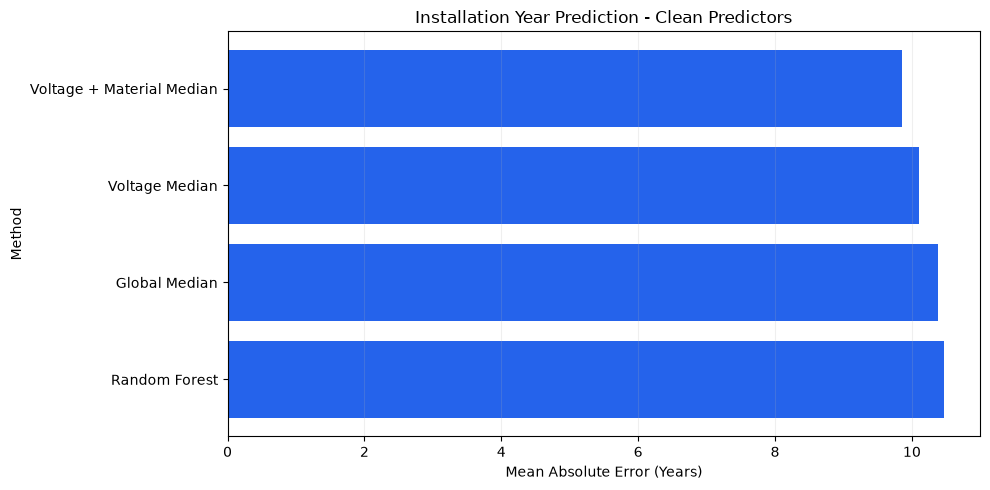

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    results_df["method"],
    results_df["MAE"],
    color="#2563eb",
)

ax.set_title(
    "Installation Year Prediction - Clean Predictors"
)

ax.set_xlabel("Mean Absolute Error (Years)")
ax.set_ylabel("Method")

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [18]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Use existing notebook DataFrames
clean_df = clean
masked_df = masked[0]

TARGET = "installation_year"

feature_sets = {
    "A1_All_Features": [
        "distance_to_sea_km",
        "voltage_category",
        "location_group",
        "corrosion_zone",
        "material",
        "covering",
    ],

    "A2_Without_Voltage": [
        "distance_to_sea_km",
        "location_group",
        "corrosion_zone",
        "material",
        "covering",
    ],

    "A3_Without_Material": [
        "distance_to_sea_km",
        "voltage_category",
        "location_group",
        "corrosion_zone",
        "covering",
    ],

    "A4_Without_Both": [
        "distance_to_sea_km",
        "location_group",
        "corrosion_zone",
        "covering",
    ],

    "A5_Only_Voltage_Material": [
        "voltage_category",
        "material",
    ],
}

# Identical training and evaluation rows
test_mask = masked_df[TARGET].isna().to_numpy()
train_mask = ~test_mask

assert test_mask.sum() == 2000
assert train_mask.sum() == 8000
assert len(clean_df) == len(masked_df)

# Never train on the hidden installation-year labels
y_train = clean_df.loc[train_mask, TARGET]
y_test = clean_df.loc[test_mask, TARGET]

assert np.array_equal(
    masked_df.loc[train_mask, TARGET].to_numpy(),
    y_train.to_numpy(),
)

results = []
predictions = {}

for experiment, features in feature_sets.items():

    numeric = [
        c for c in features
        if c == "distance_to_sea_km"
    ]

    categorical = [
        c for c in features
        if c != "distance_to_sea_km"
    ]

    transformers = []

    if numeric:
        transformers.append(
            ("numeric", "passthrough", numeric)
        )

    if categorical:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical,
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=8,
                min_samples_leaf=5,
                random_state=219,
                n_jobs=-1,
            ),
        ),
    ])

    # Clean predictors for controlled relationship study
    X_train = clean_df.loc[train_mask, features]
    X_test = clean_df.loc[test_mask, features]

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # Installation-year constraints
    y_pred = np.clip(
        np.rint(y_pred),
        1930,
        2014,
    )

    predictions[experiment] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "experiment": experiment,
        "n_features": len(features),
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
    })

ablation_results = pd.DataFrame(results)

baseline_mae = ablation_results.loc[
    ablation_results["experiment"] == "A1_All_Features",
    "mae",
].iloc[0]

ablation_results["mae_change"] = (
    ablation_results["mae"] - baseline_mae
)

print("=== INSTALLATION YEAR FEATURE ABLATION ===")

display(ablation_results.round(4))

=== INSTALLATION YEAR FEATURE ABLATION ===


,experiment,n_features,mae,rmse,r2,mae_change
0,A1_All_Features,6,10.4710,13.5536,0.0923,0.0000
1,A2_Without_Voltage,5,10.8270,14.0699,0.0218,0.3560
2,A3_Without_Material,5,10.6200,13.6787,0.0754,0.1490
3,A4_Without_Both,4,11.0115,14.2214,0.0006,0.5405
4,A5_Only_Voltage_Material,2,10.3970,13.4598,0.1048,-0.0740


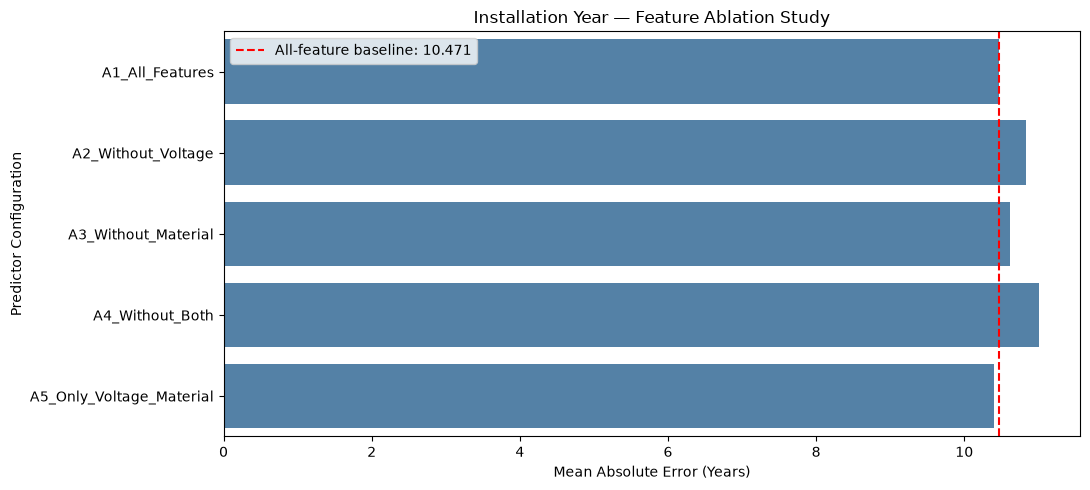

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 5))

sns.barplot(
    data=ablation_results,
    x="mae",
    y="experiment",
    color="steelblue",
)

plt.axvline(
    baseline_mae,
    color="red",
    linestyle="--",
    label=f"All-feature baseline: {baseline_mae:.3f}",
)

plt.title(
    "Installation Year — Feature Ablation Study"
)

plt.xlabel("Mean Absolute Error (Years)")
plt.ylabel("Predictor Configuration")

plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import numpy as np

rng = np.random.default_rng(219)

actual = np.asarray(y_test)

comparison_pairs = [
    (
        "A1_All_Features",
        "A2_Without_Voltage",
    ),
    (
        "A1_All_Features",
        "A3_Without_Material",
    ),
    (
        "A1_All_Features",
        "A4_Without_Both",
    ),
    (
        "A1_All_Features",
        "A5_Only_Voltage_Material",
    ),
]

results_ci = []

n_bootstrap = 5000
n = len(actual)

for baseline, alternative in comparison_pairs:

    baseline_error = np.abs(
        actual - predictions[baseline]
    )

    alternative_error = np.abs(
        actual - predictions[alternative]
    )

    # Positive = alternative performs worse
    differences = alternative_error - baseline_error

    bootstrap_means = []

    for _ in range(n_bootstrap):
        indices = rng.integers(0, n, size=n)

        bootstrap_means.append(
            differences[indices].mean()
        )

    ci_lower, ci_upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5],
    )

    results_ci.append({
        "comparison": alternative,
        "mae_difference": differences.mean(),
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
    })

confidence_results = pd.DataFrame(results_ci)

display(confidence_results.round(4))

,comparison,mae_difference,ci_lower,ci_upper
0,A2_Without_Voltage,0.3560,0.1840,0.5240
1,A3_Without_Material,0.1490,0.0285,0.2715
2,A4_Without_Both,0.5405,0.3500,0.7390
3,A5_Only_Voltage_Material,-0.0740,-0.1600,0.0145
